In [4]:
# ========== Standard Library & Data Handling Imports ==========
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import pickle
import os

# ========== Scikit-learn & ML Tools ==========
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [5]:
# Load the datasets


df_payments = pd.read_csv('synthetic_sme_payments.csv')
df_cash_flow = pd.read_csv('synthetic_sme_daily_cash_flow.csv')
df_expenses = pd.read_csv('synthetic_sme_expenses.csv')
df_invoices = pd.read_csv('synthetic_sme_invoices.csv')

# Assign datasets
df = df_payments
df1 = df_cash_flow
df2 = df_expenses
df3 = df_invoices


In [6]:
# Display preview of df (Payments)
print("Payments (df) Preview:")
df.head()


Payments (df) Preview:


,payment_id,business_id,payment_date,invoice_id,amount_egp,payment_delay_days
0,PAY_0000001,SME_001,2023-01-31,INV_SME_001_20230101_0000,3536.77,0
1,PAY_0000002,SME_001,2023-02-08,INV_SME_001_20230102_0001,6580.53,7
2,PAY_0000003,SME_001,2023-02-17,INV_SME_001_20230103_0002,9817.09,0
3,PAY_0000004,SME_001,2023-02-03,INV_SME_001_20230104_0003,8887.91,0
4,PAY_0000005,SME_001,2023-02-19,INV_SME_001_20230105_0004,3874.79,0


In [7]:
# Summary statistics of df
df.describe().T


,count,mean,std,min,25%,50%,75%,max
amount_egp,8764.0,3986.985134,2717.927163,289.25,2014.2175,3100.31,5363.5425,21364.94
payment_delay_days,8764.0,3.780123,11.011418,0.00,0.0000,0.00,0.0000,60.00


In [8]:
# Dataset shape
print("df Shape:", df.shape)


df Shape: (8764, 6)


In [9]:
# Value counts of businesses
df['business_id'].value_counts()


business_id
SME_002    1096
SME_004    1096
SME_007    1096
SME_005    1096
SME_008    1096
SME_001    1095
SME_003    1095
SME_006    1094
Name: count, dtype: int64

In [10]:
# Check for missing values
df.isnull().sum()


payment_id            0
business_id           0
payment_date          0
invoice_id            0
amount_egp            0
payment_delay_days    0
dtype: int64

In [11]:
# Check for duplicates
df.duplicated().sum()


np.int64(0)

In [12]:
# Distribution of target: payment_delay_days
df['payment_delay_days'].value_counts().head(10)


payment_delay_days
0     7080
14     450
7      405
30     349
3      268
60     212
Name: count, dtype: int64

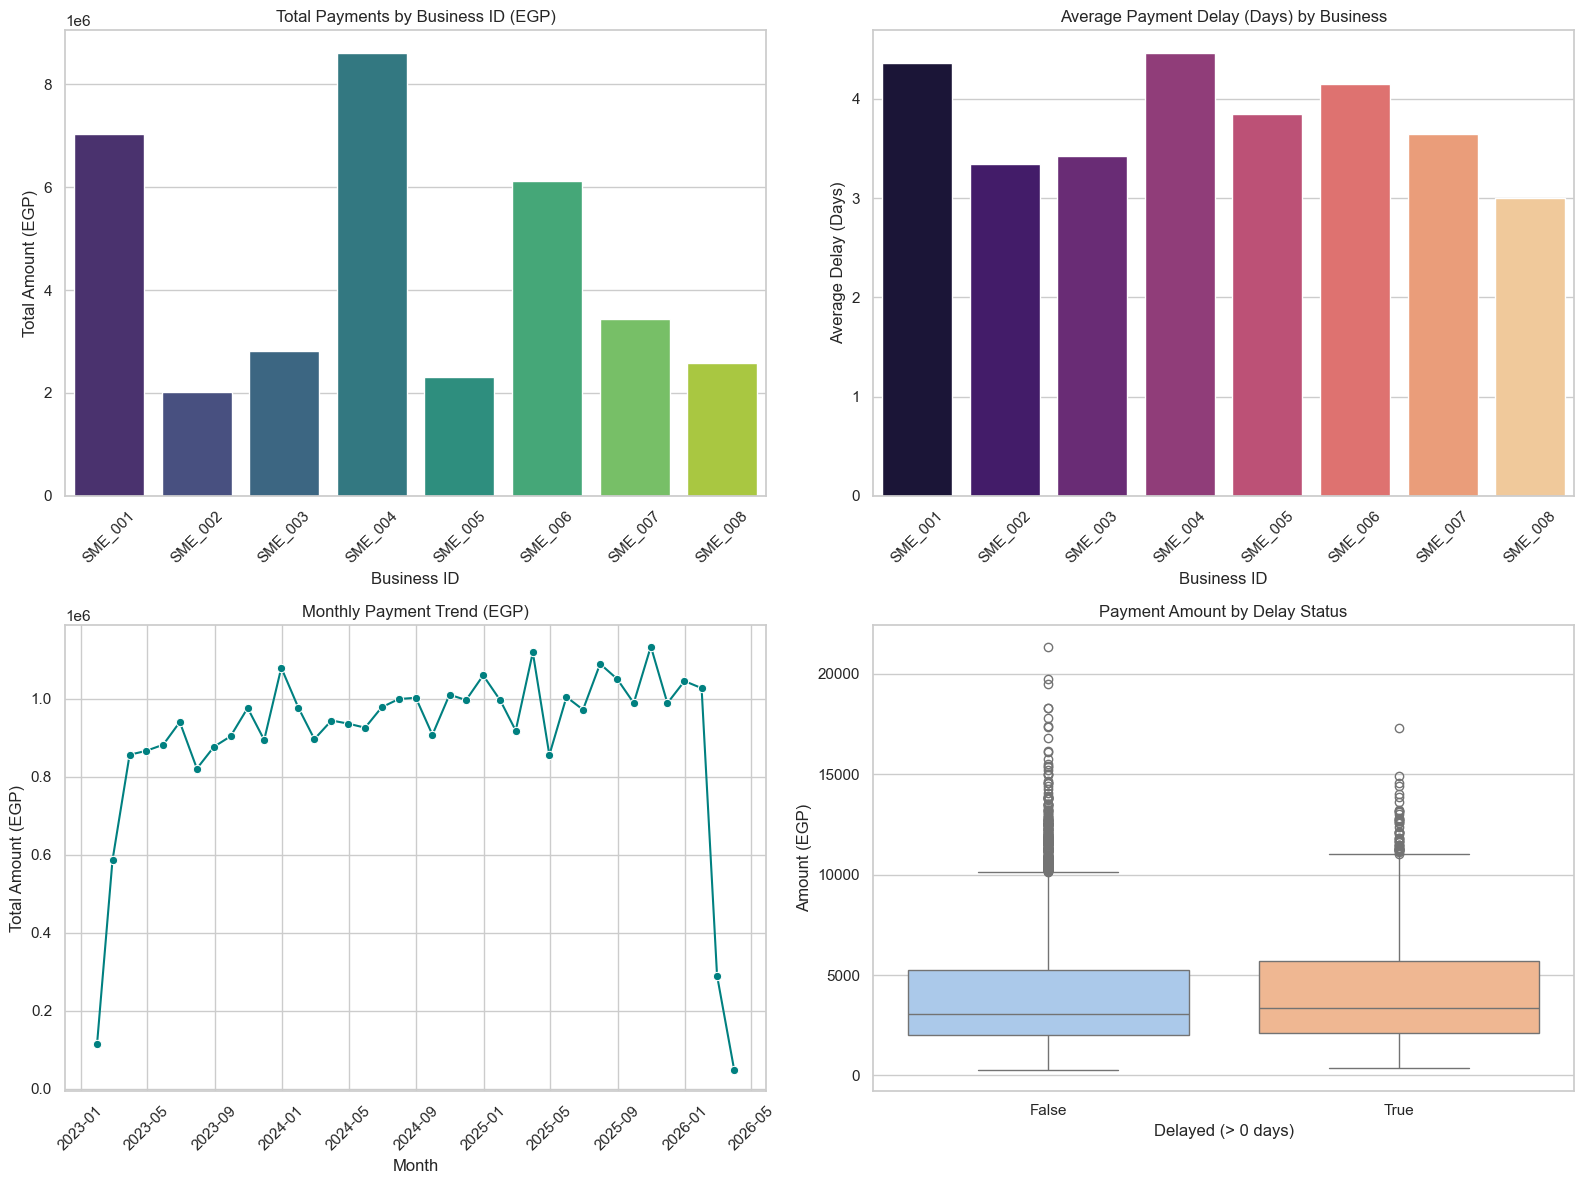

In [13]:
# ========== Visualizations for df (Payments) ==========
df_viz = df.copy()
df_viz['payment_date'] = pd.to_datetime(df_viz['payment_date'])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Total Payment Amount by Business
sns.barplot(
    ax=axes[0, 0],
    x=df_viz.groupby('business_id')['amount_egp'].sum().index,
    y=df_viz.groupby('business_id')['amount_egp'].sum().values,
    palette='viridis'
)
axes[0, 0].set_title('Total Payments by Business ID (EGP)')
axes[0, 0].set_xlabel('Business ID')
axes[0, 0].set_ylabel('Total Amount (EGP)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Average Payment Delay Days by Business
sns.barplot(
    ax=axes[0, 1],
    x=df_viz.groupby('business_id')['payment_delay_days'].mean().index,
    y=df_viz.groupby('business_id')['payment_delay_days'].mean().values,
    palette='magma'
)
axes[0, 1].set_title('Average Payment Delay (Days) by Business')
axes[0, 1].set_xlabel('Business ID')
axes[0, 1].set_ylabel('Average Delay (Days)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Monthly Payments Trend
df_monthly = df_viz.set_index('payment_date').resample('ME')['amount_egp'].sum().reset_index()
sns.lineplot(
    ax=axes[1, 0],
    data=df_monthly,
    x='payment_date',
    y='amount_egp',
    marker='o',
    color='teal'
)
axes[1, 0].set_title('Monthly Payment Trend (EGP)')
axes[1, 0].set_xlabel('Month')
axes[1, 0].set_ylabel('Total Amount (EGP)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Boxplot of Payment Amount by Delay Flag (On-time vs Delayed)
df_viz['is_delayed'] = df_viz['payment_delay_days'] > 0
sns.boxplot(
    ax=axes[1, 1],
    data=df_viz,
    x='is_delayed',
    y='amount_egp',
    palette='pastel'
)
axes[1, 1].set_title('Payment Amount by Delay Status')
axes[1, 1].set_xlabel('Delayed (> 0 days)')
axes[1, 1].set_ylabel('Amount (EGP)')

plt.tight_layout()
plt.show()


In [14]:
# ========== Preprocessing & Feature Engineering ==========
df_encoded = df.copy()

# Date feature extraction
df_encoded['payment_date'] = pd.to_datetime(df_encoded['payment_date'])
df_encoded['year'] = df_encoded['payment_date'].dt.year
df_encoded['month'] = df_encoded['payment_date'].dt.month
df_encoded['day'] = df_encoded['payment_date'].dt.day
df_encoded['day_of_week'] = df_encoded['payment_date'].dt.dayofweek

# Drop non-feature ID and date columns
df_encoded.drop(columns=['payment_date', 'payment_id', 'invoice_id'], inplace=True)

# Encode business_id
le_pay = LabelEncoder()
df_encoded['business_id'] = le_pay.fit_transform(df_encoded['business_id'])

print("Encoded df preview:")
df_encoded.head()


Encoded df preview:


,business_id,amount_egp,payment_delay_days,year,month,day,day_of_week
0,0,3536.77,0,2023,1,31,1
1,0,6580.53,7,2023,2,8,2
2,0,9817.09,0,2023,2,17,4
3,0,8887.91,0,2023,2,3,4
4,0,3874.79,0,2023,2,19,6


In [15]:
# Separate Features (X) and Target (y: payment_delay_days)
X = df_encoded.drop('payment_delay_days', axis=1)
y = df_encoded['payment_delay_days']

# Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")


X_train shape: (7011, 6), X_test shape: (1753, 6)


In [16]:
# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Data Scaling Complete!")
X_train_scaled_df.head()


Data Scaling Complete!


,business_id,amount_egp,year,month,day,day_of_week
0,0.657422,1.343116,-0.112772,-0.156964,-1.429007,-1.517958
1,1.533692,0.178049,-0.112772,0.714353,1.055330,-0.512250
2,-1.533255,1.144675,-1.268680,-0.447403,1.168255,0.493458
3,-0.218849,0.068914,-1.268680,-0.447403,1.168255,0.493458
4,-1.095120,-0.410507,-0.112772,1.585670,-0.638536,-1.015104


In [17]:
# ========== Model Training & Evaluation ==========
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree Regressor': DecisionTreeRegressor(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_estimators=100),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'XGBoost Regressor': XGBRegressor(random_state=42)
}

results = {}
print("=== Training Regression Models on Payments ===\n")

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results[name] = {
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

results_df = pd.DataFrame(results).T
print("\n=== Model Comparison Results ===")
display(results_df.sort_values(by='MAE', ascending=True))


=== Training Regression Models on Payments ===

Training Linear Regression...
Training Decision Tree Regressor...
Training Random Forest Regressor...
Training Gradient Boosting Regressor...
Training XGBoost Regressor...

=== Model Comparison Results ===


,MAE,MSE,RMSE,R2 Score
Gradient Boosting Regressor,6.060513,119.107776,10.913651,0.008168
Linear Regression,6.090090,119.699273,10.940716,0.003242
XGBoost Regressor,6.674181,141.813568,11.908550,-0.180908
Random Forest Regressor,6.829743,131.914533,11.485405,-0.098476
Decision Tree Regressor,7.539076,268.483742,16.385474,-1.235713


In [18]:
# ========== Hyperparameter Fine-Tuning ==========
print("=== Hyperparameter Fine-tuning Random Forest ===\n")

rf_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10]
}

rf_grid = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=5,
    scoring='r2',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=1
)
rf_grid.fit(X_train_scaled, y_train)

best_rf = rf_grid.best_estimator_
rf_predictions = best_rf.predict(X_test_scaled)
print(f"Best RF Params: {rf_grid.best_params_}")
print(f"Fine-tuned RF MAE: {mean_absolute_error(y_test, rf_predictions):.4f}")


=== Hyperparameter Fine-tuning Random Forest ===

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best RF Params: {'n_estimators': 150, 'min_samples_split': 10, 'max_depth': 5}
Fine-tuned RF MAE: 6.0679


In [19]:
# ========== Save Model and Scaler ==========
with open('best_pay_model.pkl', 'wb') as f:
    pickle.dump(best_rf, f)

with open('scaler_pay.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('le_pay.pkl', 'wb') as f:
    pickle.dump(le_pay, f)

print("Saved 'best_pay_model.pkl', 'scaler_pay.pkl', and 'le_pay.pkl' successfully!")


Saved 'best_pay_model.pkl', 'scaler_pay.pkl', and 'le_pay.pkl' successfully!


### طريقة تشغيل الـ FastAPI والتجربة
في الخلية التالية يتم كتابة وتشغيل خادم الـ API لتوقع تأخير المدفوعات `payment_delay_days`:


In [20]:
# Test Sample Prediction
sample_input = np.array([[0, 5000.0, 2024, 6, 15, 5]]) # [business_id, amount_egp, year, month, day, day_of_week]
scaled_sample = scaler.transform(sample_input)
pred_delay = best_rf.predict(scaled_sample)[0]
print(f"Predicted Payment Delay: {pred_delay:.2f} Days")


Predicted Payment Delay: 3.87 Days
